In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, load_digits
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture

import warnings
warnings.filterwarnings('ignore')

import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'

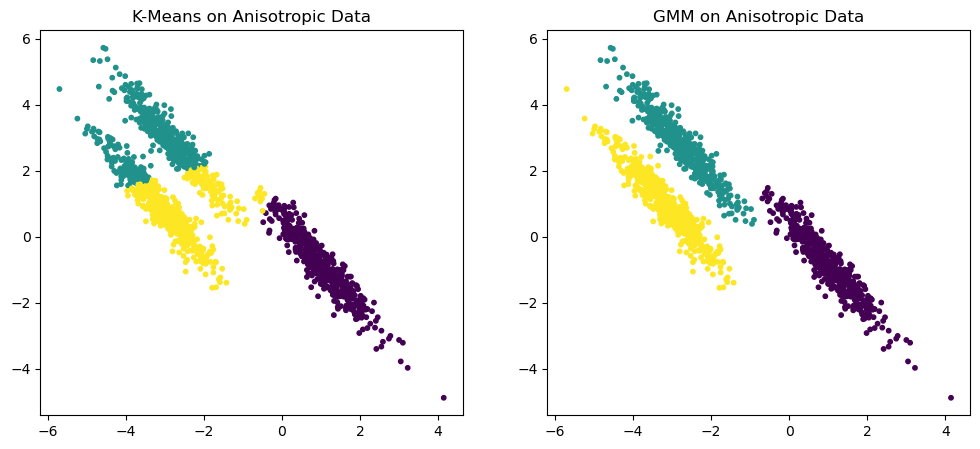

In [2]:
X, y = make_blobs(n_samples=1500, centers=3, cluster_std=1.0, random_state=170)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)

kmeans = KMeans(n_clusters=3, random_state=170).fit(X_aniso)
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=170).fit(X_aniso)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_aniso[:, 0], X_aniso[:, 1], c=kmeans.labels_, s=10)
plt.title("K-Means on Anisotropic Data")
plt.subplot(1, 2, 2)
plt.scatter(X_aniso[:, 0], X_aniso[:, 1], c=gmm.predict(X_aniso), s=10)
plt.title("GMM on Anisotropic Data")
plt.savefig("figs/kmeans_gmm_comparison.png", bbox_inches="tight")
plt.show()

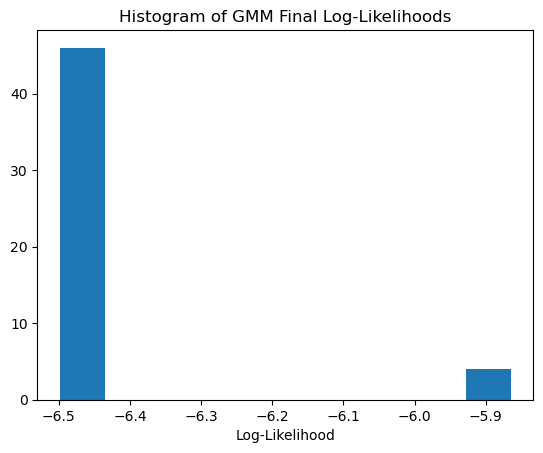

In [3]:
X_diff, _ = make_blobs(n_samples=500, centers=4, cluster_std=2.5, random_state=42)
log_likelihoods = []

for i in range(50):
    gmm_iter = GaussianMixture(n_components=4, init_params='random', n_init=1, random_state=i)
    gmm_iter.fit(X_diff)
    log_likelihoods.append(gmm_iter.lower_bound_)

plt.figure()
plt.hist(log_likelihoods)
plt.title("Histogram of GMM Final Log-Likelihoods")
plt.xlabel("Log-Likelihood")
plt.savefig("figs/kmeans_gmm_comparison.png", bbox_inches="tight")
plt.show()

In [4]:
X_outlier = np.vstack([X[:100], [10, 10]])
gmm_sing = GaussianMixture(n_components=2, reg_covar=0, init_params='random', random_state=42)
gmm_sing.means_init = np.array([X[0], [15, 15]])

try:
    gmm_sing.fit(X_outlier)
except Exception as e:
    print(f"Caught expected singularity error: {e}")

Caught expected singularity error: Fitting the mixture model failed because some components have ill-defined empirical covariance (for instance caused by singleton or collapsed samples). Try to decrease the number of components, increase reg_covar, or scale the input data.


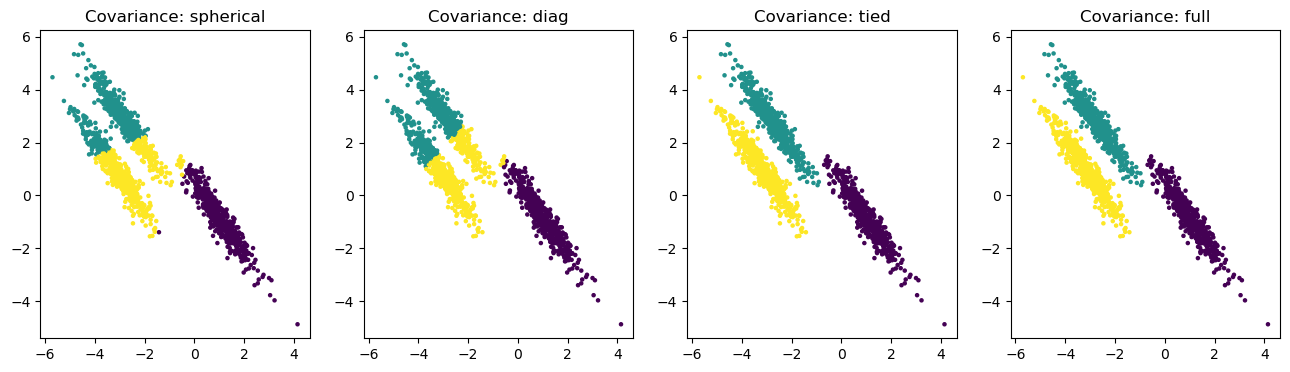

In [5]:
cov_types = ['spherical', 'diag', 'tied', 'full']
plt.figure(figsize=(16, 4))
for i, cov in enumerate(cov_types):
    model = GaussianMixture(n_components=3, covariance_type=cov, random_state=170).fit(X_aniso)
    plt.subplot(1, 4, i+1)
    plt.scatter(X_aniso[:, 0], X_aniso[:, 1], c=model.predict(X_aniso), s=5)
    plt.title(f"Covariance: {cov}")
plt.savefig("figs/covariance_comparison.png", bbox_inches="tight")
plt.show()


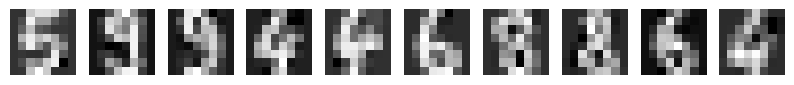

In [6]:
digits = load_digits()
gmm_gen = GaussianMixture(n_components=30, covariance_type='full', random_state=42)
gmm_gen.fit(digits.data)

new_data, _ = gmm_gen.sample(10)
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(new_data[i].reshape(8, 8), cmap='gray')
    plt.axis('off')
plt.savefig("figs/generated_digits.png", bbox_inches="tight")
plt.show()

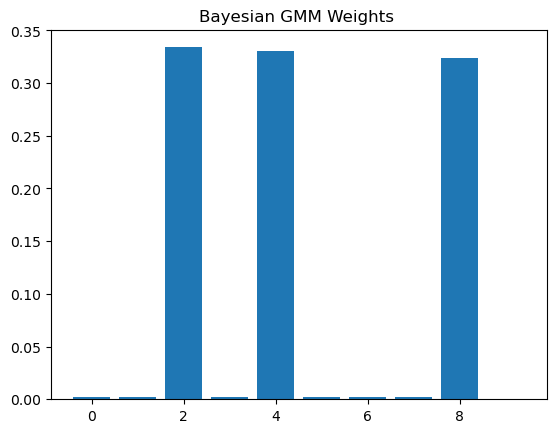

In [7]:
X_bgmm, _ = make_blobs(n_samples=500, centers=3, random_state=42)
bgmm = BayesianGaussianMixture(n_components=10, weight_concentration_prior=1e-3, random_state=42)
bgmm.fit(X_bgmm)

plt.figure()
plt.bar(range(10), bgmm.weights_)
plt.title("Bayesian GMM Weights ")
plt.show()